# Tutorial 12: Basic Auto Encoders


## Import Libraries

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

import numpy as np
import matplotlib.pyplot as plt

# use gpu if we have one
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


## Load Data Set



In [2]:
transform = transforms.ToTensor()

train_data = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
test_data = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

BATCH_SIZE = 128
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False)

print("Train images:", len(train_data))
print("Test images:", len(test_data))
print("One image shape:", train_data[0][0].shape)

100%|██████████| 9.91M/9.91M [00:00<00:00, 37.2MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.13MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 9.66MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 5.33MB/s]


Train images: 60000
Test images: 10000
One image shape: torch.Size([1, 28, 28])


In [3]:
class BasicAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        # encoder: 28x28 -> 14x14 -> 7x7
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        # decoder: 7x7 -> 14x14 -> 28x28
        self.decoder = nn.Sequential(
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Upsample(scale_factor=2),
            nn.Conv2d(64, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Upsample(scale_factor=2),
            nn.Conv2d(32, 1, kernel_size=3, padding=1),
            nn.Sigmoid(),
        )

    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded


basic_model = BasicAutoencoder().to(device)
print(basic_model)

# quick check that output shape = input shape
test_batch = torch.randn(4, 1, 28, 28).to(device)
print("Output shape:", basic_model(test_batch).shape)

BasicAutoencoder(
  (encoder): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (decoder): Sequential(
    (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Upsample(scale_factor=2.0, mode='nearest')
    (3): Conv2d(64, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): Upsample(scale_factor=2.0, mode='nearest')
    (6): Conv2d(32, 1, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): Sigmoid()
  )
)
Output shape: torch.Size([4, 1, 28, 28])


## Train the Autoencoder



In [4]:
EPOCHS = 10
LR = 1e-3

def train_model(model, epochs=EPOCHS, lr=LR):
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    train_losses, test_losses = [], []

    for epoch in range(epochs):
        # ---- training ----
        model.train()
        running = 0.0
        for imgs, _ in train_loader:          # labels are not needed
            imgs = imgs.to(device)
            output = model(imgs)
            loss = criterion(output, imgs)    # compare output with the input itself

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            running += loss.item() * imgs.size(0)
        train_loss = running / len(train_loader.dataset)

        # ---- validation on test set ----
        model.eval()
        running = 0.0
        with torch.no_grad():
            for imgs, _ in test_loader:
                imgs = imgs.to(device)
                loss = criterion(model(imgs), imgs)
                running += loss.item() * imgs.size(0)
        test_loss = running / len(test_loader.dataset)

        train_losses.append(train_loss)
        test_losses.append(test_loss)
        print(f"Epoch {epoch+1}/{epochs} - train loss: {train_loss:.5f} - test loss: {test_loss:.5f}")

    return train_losses, test_losses

In [5]:
basic_train_losses, basic_test_losses = train_model(basic_model)

Epoch 1/10 - train loss: 0.11314 - test loss: 0.11396
Epoch 2/10 - train loss: 0.11200 - test loss: 0.11396
Epoch 3/10 - train loss: 0.11200 - test loss: 0.11396
Epoch 4/10 - train loss: 0.11200 - test loss: 0.11396
Epoch 5/10 - train loss: 0.11200 - test loss: 0.11396
Epoch 6/10 - train loss: 0.11200 - test loss: 0.11396
Epoch 7/10 - train loss: 0.11200 - test loss: 0.11396
Epoch 8/10 - train loss: 0.11200 - test loss: 0.11396
Epoch 9/10 - train loss: 0.11200 - test loss: 0.11396
Epoch 10/10 - train loss: 0.11200 - test loss: 0.11396


## Visualize the Results

Now we compare original test images (top row) with the reconstructed ones (bottom row).

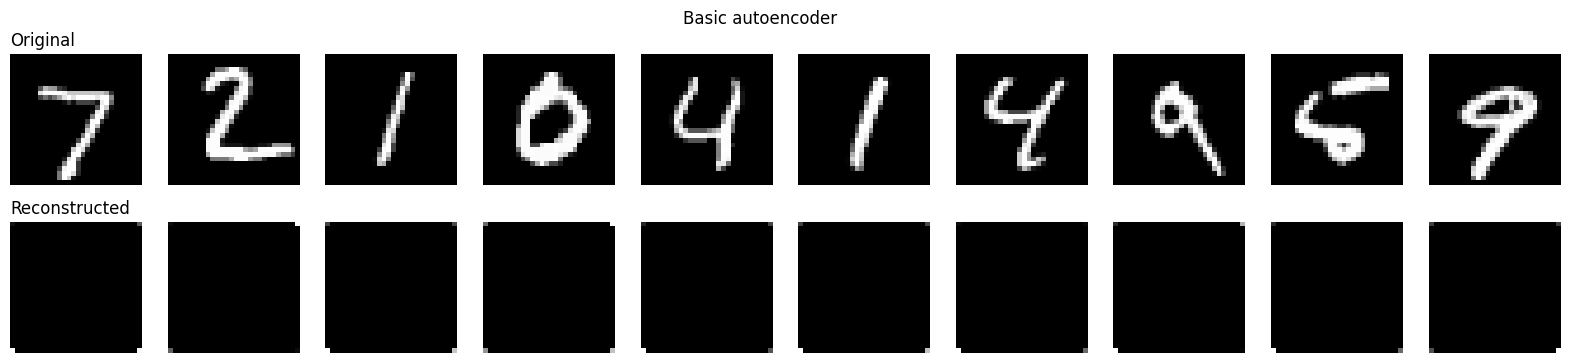

In [9]:
def show_results(model, n=10, title="Model"):
    model.eval()
    imgs, _ = next(iter(test_loader))
    imgs = imgs[:n].to(device)
    with torch.no_grad():
        decoded_imgs = model(imgs).cpu()
    imgs = imgs.cpu()

    plt.figure(figsize=(20, 4))
    for i in range(n):
        # original
        ax = plt.subplot(2, n, i + 1)
        plt.imshow(imgs[i].reshape(28, 28), cmap="gray")
        ax.axis("off")
        if i == 0:
            ax.set_title("Original", loc="left")

        # reconstructed
        ax = plt.subplot(2, n, i + 1 + n)
        plt.imshow(decoded_imgs[i].reshape(28, 28), cmap="gray")
        ax.axis("off")
        if i == 0:
            ax.set_title("Reconstructed", loc="left")
    plt.suptitle(title)
    plt.show()

show_results(basic_model, title="Basic autoencoder")

## Task: Improve the Model



In [7]:
def conv_block(in_ch, out_ch, stride=1):
    return nn.Sequential(
        nn.Conv2d(in_ch, out_ch, kernel_size=3, stride=stride, padding=1),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(),
    )

def deconv_block(in_ch, out_ch):
    # stride 2 doubles the height and width (7 -> 14 -> 28)
    return nn.Sequential(
        nn.ConvTranspose2d(in_ch, out_ch, kernel_size=3, stride=2, padding=1, output_padding=1),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(),
    )


class DeepAutoencoder(nn.Module):
    def __init__(self, latent_dim=None):
        super().__init__()
        self.latent_dim = latent_dim

        # encoder: 28x28 -> 14x14 -> 7x7
        self.encoder = nn.Sequential(
            conv_block(1, 32),
            conv_block(32, 32, stride=2),    # 14x14
            conv_block(32, 64),
            conv_block(64, 64, stride=2),    # 7x7
        )

        # optional dense latent layer
        if latent_dim is not None:
            self.fc_enc = nn.Linear(64 * 7 * 7, latent_dim)
            self.fc_dec = nn.Linear(latent_dim, 64 * 7 * 7)

        # decoder: 7x7 -> 14x14 -> 28x28
        self.decoder = nn.Sequential(
            conv_block(64, 64),
            deconv_block(64, 32),            # 14x14
            conv_block(32, 32),
            deconv_block(32, 32),            # 28x28
            nn.Conv2d(32, 1, kernel_size=3, padding=1),
            nn.Sigmoid(),
        )

    def forward(self, x):
        x = self.encoder(x)
        if self.latent_dim is not None:
            z = self.fc_enc(x.flatten(1))                 # latent vector
            x = torch.relu(self.fc_dec(z)).view(-1, 64, 7, 7)
        return self.decoder(x)


deep_model = DeepAutoencoder().to(device)
print("Output shape:", deep_model(torch.randn(4, 1, 28, 28).to(device)).shape)
print("Deep model params:", sum(p.numel() for p in deep_model.parameters()))
print("Basic model params:", sum(p.numel() for p in basic_model.parameters()))

Output shape: torch.Size([4, 1, 28, 28])
Deep model params: 139873
Basic model params: 74497


### Model 2: Deeper conv autoencoder

Epoch 1/10 - train loss: 0.00683 - test loss: 0.00098
Epoch 2/10 - train loss: 0.00077 - test loss: 0.00054
Epoch 3/10 - train loss: 0.00052 - test loss: 0.00045
Epoch 4/10 - train loss: 0.00041 - test loss: 0.00035
Epoch 5/10 - train loss: 0.00032 - test loss: 0.00028
Epoch 6/10 - train loss: 0.00027 - test loss: 0.00023
Epoch 7/10 - train loss: 0.00024 - test loss: 0.00023
Epoch 8/10 - train loss: 0.00021 - test loss: 0.00017
Epoch 9/10 - train loss: 0.00019 - test loss: 0.00018
Epoch 10/10 - train loss: 0.00017 - test loss: 0.00019


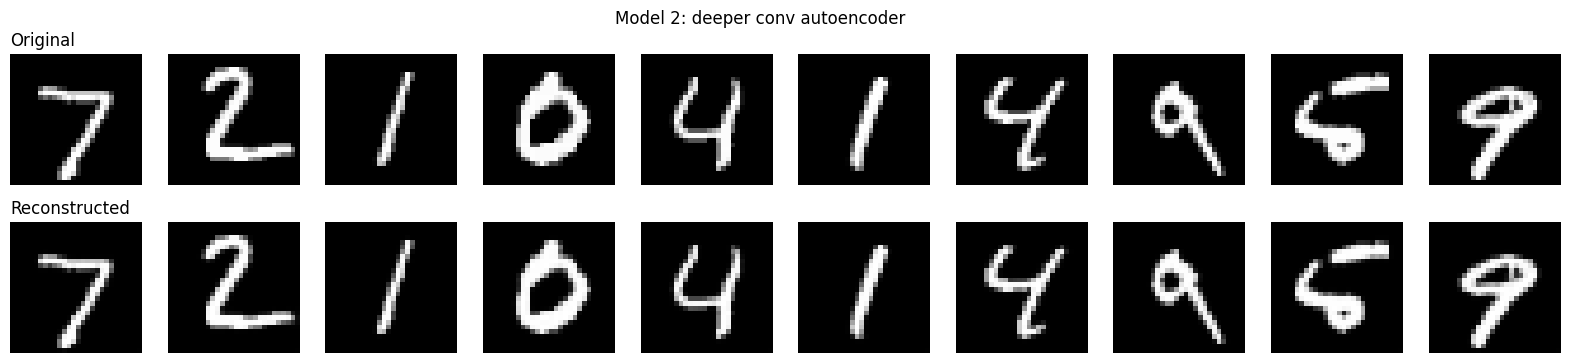

In [8]:
deep_train_losses, deep_test_losses = train_model(deep_model)
show_results(deep_model, title="Model 2: deeper conv autoencoder")

### Model 3: Deeper conv autoencoder with a dense latent layer (32 values)

Epoch 1/10 - train loss: 0.01971 - test loss: 0.00568
Epoch 2/10 - train loss: 0.00501 - test loss: 0.00446
Epoch 3/10 - train loss: 0.00416 - test loss: 0.00386
Epoch 4/10 - train loss: 0.00375 - test loss: 0.00370
Epoch 5/10 - train loss: 0.00350 - test loss: 0.00334
Epoch 6/10 - train loss: 0.00334 - test loss: 0.00338
Epoch 7/10 - train loss: 0.00317 - test loss: 0.00315
Epoch 8/10 - train loss: 0.00310 - test loss: 0.00305
Epoch 9/10 - train loss: 0.00297 - test loss: 0.00358
Epoch 10/10 - train loss: 0.00293 - test loss: 0.00287


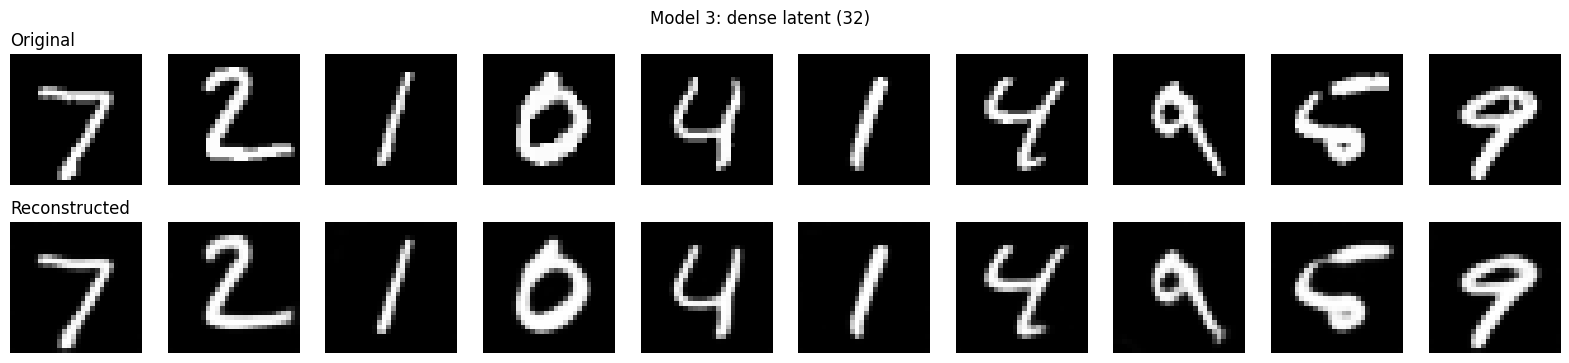

In [10]:
latent_model = DeepAutoencoder(latent_dim=32).to(device)
latent_train_losses, latent_test_losses = train_model(latent_model)
show_results(latent_model, title="Model 3: dense latent (32)")

## Compare the Models

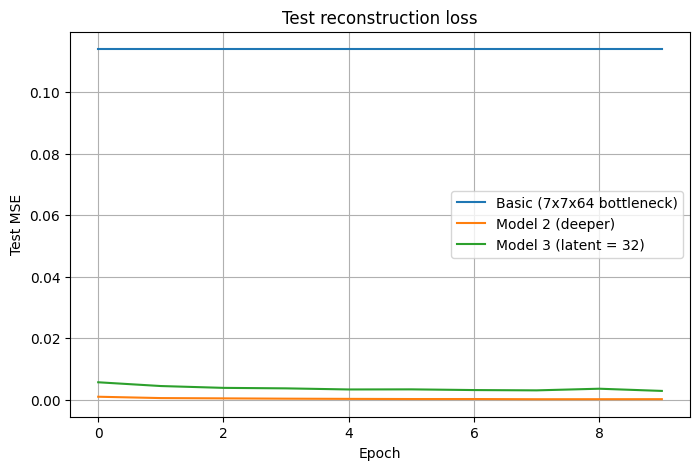


--- Final Test MSE Metrics ---
Basic      final test MSE: 0.11396
Model 2    final test MSE: 0.00019
Model 3    final test MSE: 0.00287


In [16]:
# loss curves
plt.figure(figsize=(8, 5))

# Dynamically plot only the models that have been run in this session
models_to_plot = []
if 'basic_test_losses' in locals():
    plt.plot(basic_test_losses, label="Basic (7x7x64 bottleneck)")
    models_to_plot.append(("Basic", basic_test_losses))
else:
    print("Note: Basic model loss ('basic_test_losses') is missing. Run cell pBc4oLV8HAMH to include it.")

if 'deep_test_losses' in locals():
    plt.plot(deep_test_losses, label="Model 2 (deeper)")
    models_to_plot.append(("Model 2", deep_test_losses))

if 'latent_test_losses' in locals():
    plt.plot(latent_test_losses, label="Model 3 (latent = 32)")
    models_to_plot.append(("Model 3", latent_test_losses))

plt.xlabel("Epoch")
plt.ylabel("Test MSE")
plt.title("Test reconstruction loss")
plt.legend()
plt.grid(True)
plt.show()

# final numbers
print("\n--- Final Test MSE Metrics ---")
for name, losses in models_to_plot:
    print(f"{name:<10} final test MSE: {losses[-1]:.5f}")

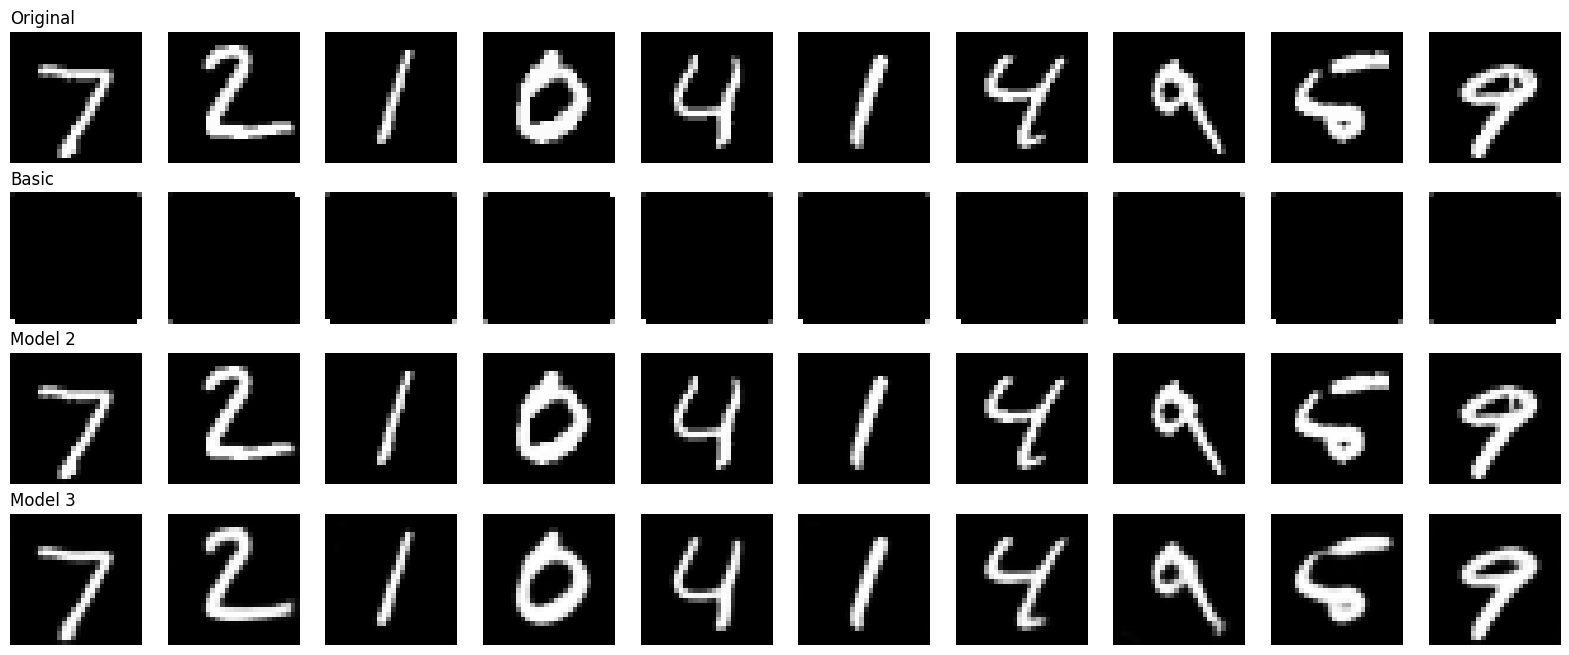

In [17]:
# all three models on the same 10 test images
imgs, _ = next(iter(test_loader))
imgs = imgs[:10].to(device)

rows = [("Original", imgs.cpu())]
for name, m in [("Basic", basic_model), ("Model 2", deep_model), ("Model 3", latent_model)]:
    m.eval()
    with torch.no_grad():
        rows.append((name, m(imgs).cpu()))

plt.figure(figsize=(20, 8))
for r, (name, data) in enumerate(rows):
    for i in range(10):
        ax = plt.subplot(len(rows), 10, r * 10 + i + 1)
        plt.imshow(data[i].reshape(28, 28), cmap="gray")
        ax.axis("off")
        if i == 0:
            ax.set_title(name, loc="left")
plt.show()